# Next product Top-K prediction
## 1. Introduction
Given the current click and information available so far, this study scores and ranks candidate products for the next click within an e-commerce browsing session. It treats session-based next-item prediction as multiclass classification followed by Top-K ranking. The target exists only when another click occurs in the same session.

An e-commerce site could use the Top-K list as product candidates for a recommendation interface. Offline ranking performance does not establish that displaying these candidates would improve purchases, revenue or customer satisfaction.

The research questions are:

- **RQ1:** Do Machine Learning models outperform Global Popularity and First-Order Markov baselines?
- **RQ2:** Do contextual and historical features improve next-product ranking?
- **RQ3:** How effectively is the actual next product ranked within Top-K?

**Hit Rate@5** is the primary selection and evaluation metric; **MRR@10** provides a secondary measure of rank position. Model and feature selection use grouped training cross-validation. The test holdout was inspected during earlier project development, so it is not a fresh confirmation set.

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits

RANDOM_STATE = 42
thread_limits = threadpool_limits(limits=2)
pd.set_option("display.max_columns", 15)
sns.set_theme(style="whitegrid")
display(pd.Series({"Python": platform.python_version(), "pandas": pd.__version__,
                   "numpy": np.__version__, "scikit-learn": sklearn.__version__}, name="Version").to_frame())

,Version
Python,3.11.4
pandas,2.3.3
numpy,2.3.3
scikit-learn,1.7.2


## 2. Data understanding
The 2008 clickstream records product views, session identifiers, click order, product attributes and browsing context. The supplied `ORDER` defines click sequence within each session. Dates identify days but cannot independently verify the order of clicks within a day.

`Next_MODEL` is the product clicked immediately after the current product within the same session. The final click has no valid target, and single-click sessions provide no labeled observations. Terminal clicks are retained while creating labels for preceding clicks; only then are unlabeled rows excluded from modeling.

In [2]:
df = pd.read_csv("e-shop clothing 2008.csv")
df.index.name = "Row_ID"
df = df.rename(columns={
    "year": "YEAR", "month": "MONTH", "day": "DAY", "order": "ORDER",
    "country": "COUNTRY", "session ID": "SESSION_ID",
    "page 1 (main category)": "CATEGORY", "page 2 (clothing model)": "MODEL",
    "colour": "COLOUR", "location": "LOCATION", "model photography": "PHOTOGRAPHY",
    "price": "PRICE", "price 2": "PRICE_2", "page": "PAGE"
})
print("Raw shape:", df.shape)
display(df.head())
display(df.isna().sum().rename("Missing").to_frame().T)
print("Duplicate rows:", df.duplicated().sum())
assert not df.isna().any().any() and not df.duplicated().any()

print("Number of unique models:", df["MODEL"].nunique())

Raw shape: (165474, 14)


,YEAR,MONTH,DAY,ORDER,COUNTRY,SESSION_ID,CATEGORY,MODEL,COLOUR,LOCATION,PHOTOGRAPHY,PRICE,PRICE_2,PAGE
Row_ID,,,,,,,,,,,,,,
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1


,YEAR,MONTH,DAY,ORDER,COUNTRY,SESSION_ID,CATEGORY,MODEL,COLOUR,LOCATION,PHOTOGRAPHY,PRICE,PRICE_2,PAGE
Missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Duplicate rows: 0


Number of unique models: 217


In [3]:
session_months = df[["YEAR", "MONTH", "SESSION_ID"]].drop_duplicates()
print("IDs reused across months:", session_months["SESSION_ID"].duplicated().sum())
assert not session_months["SESSION_ID"].duplicated().any(), "Reused IDs require a composite key."
assert not df.duplicated(["SESSION_ID", "ORDER"]).any()
df = df.sort_values(["SESSION_ID", "ORDER"], kind="stable").copy()
assert df["ORDER"].eq(df.groupby("SESSION_ID").cumcount() + 1).all()
click_dates = pd.to_datetime(df[["YEAR", "MONTH", "DAY"]])
assert not click_dates.groupby(df["SESSION_ID"]).diff().lt(pd.Timedelta(0)).any()
print("Validated sessions:", df["SESSION_ID"].nunique())
df["Next_MODEL"] = df.groupby("SESSION_ID", sort=False)["MODEL"].shift(-1)
print("Clicks before / after excluding final clicks:", len(df), df["Next_MODEL"].notna().sum())
assert df["Next_MODEL"].isna().sum() == df["SESSION_ID"].nunique()

IDs reused across months: 0


Validated sessions: 24026


Clicks before / after excluding final clicks: 165474 141448


The saved checks find no missing or duplicate rows, reused session IDs across months, or duplicate `(SESSION_ID, ORDER)` pairs. They validate 24,026 sessions and yield 141,448 labeled clicks from 165,474 records. These checks support the supplied sequence but do not establish within-day timestamps.

In the full CSV, A18 has 937 Category 1 records and one Category 2 record. The inconsistent assignment is retained because it cannot be verified from the supplied data.

## 3. Feature engineering and data splitting
Historical features use only the current and earlier clicks: the two previous products, price change from the preceding product, and average price before the current click. Missing history at the start of a session is retained. `Next_MODEL` and other next-click attributes are used to construct or describe outcomes, never as predictors.

In [4]:
g = df.groupby("SESSION_ID", sort=False)
df["Previous_MODEL"] = g["MODEL"].shift(1)
df["Previous_2_MODEL"] = g["MODEL"].shift(2)
df["Price_Change"] = df["PRICE"] - g["PRICE"].shift(1)
df["Average_Previous_Price"] = (g["PRICE"].cumsum() - df["PRICE"]) / g.cumcount().replace(0, np.nan)
df_model = df.loc[df["Next_MODEL"].notna()].copy()
product_features = ["MODEL", "CATEGORY", "COLOUR", "PRICE", "PRICE_2"]
context_features = ["ORDER", "PAGE", "LOCATION", "PHOTOGRAPHY"]
product_history = ["Previous_MODEL", "Previous_2_MODEL"]
price_history = ["Price_Change", "Average_Previous_Price"]
all_features = product_features + context_features + product_history + price_history
categorical_features = ["MODEL", "CATEGORY", "COLOUR", "PRICE_2", "LOCATION", "PHOTOGRAPHY"] + product_history
numerical_features = [f for f in all_features if f not in categorical_features]
for col in categorical_features + ["MONTH", "COUNTRY"]:
    df_model[col] = df_model[col].astype("category")
assert df_model.loc[df_model["ORDER"].eq(1), product_history + price_history].isna().all().all()
assert {"SESSION_ID", "Next_MODEL", "Next_PRICE", "Next_CATEGORY", "Next_COLOUR", "MONTH", "COUNTRY"}.isdisjoint(all_features)
display(df_model[["SESSION_ID", "ORDER", "MODEL"] + product_history + price_history + ["Next_MODEL"]].head(8))

,SESSION_ID,ORDER,MODEL,Previous_MODEL,Previous_2_MODEL,Price_Change,Average_Previous_Price,Next_MODEL
Row_ID,,,,,,,,
0,1,1,A13,NaN,NaN,NaN,NaN,A16
1,1,2,A16,A13,NaN,5.0,28.000000,B4
2,1,3,B4,A16,A13,19.0,30.500000,B17
3,1,4,B17,B4,A16,-14.0,37.666667,B8
4,1,5,B8,B17,B4,14.0,37.750000,C56
5,1,6,C56,B8,B17,5.0,40.600000,C57
6,1,7,C57,C56,B8,-24.0,43.333333,P67
7,1,8,P67,C57,C56,5.0,41.857143,P82


| Feature group | Variables |
| --- | --- |
| Current product | `MODEL`, `CATEGORY`, `COLOUR`, `PRICE`, `PRICE_2` |
| Browsing context | `ORDER`, `PAGE`, `LOCATION`, `PHOTOGRAPHY` |
| Product history | `Previous_MODEL`, `Previous_2_MODEL` |
| Price history | `Price_Change`, `Average_Previous_Price` |

`MONTH` and `COUNTRY` remain in the data but are excluded from the default model experiments. Session IDs and row indexes are not predictors.

### Session-level split and cross-validation
An 80/20 `GroupShuffleSplit` separates sessions into training and test sets; five fixed `GroupKFold` partitions support selection within training data. Splitting by session prevents clicks from the same session crossing a split boundary. It does not by itself rule out every source of leakage or distribution shift. Preprocessing and ranking distributions are fitted on each training partition, and the test targets are not used for selection.

In [5]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df_model, groups=df_model["SESSION_ID"]))
train_df, test_df = df_model.iloc[train_idx].copy(), df_model.iloc[test_idx].copy()

assert set(train_df["SESSION_ID"]).isdisjoint(test_df["SESSION_ID"])

X_train, y_train = train_df[all_features], train_df["Next_MODEL"]
groups_train = train_df["SESSION_ID"]
group_cv = GroupKFold(n_splits=5)
folds = list(group_cv.split(X_train, y_train, groups_train))
fold_checks = []
for fold, (tr, va) in enumerate(folds, 1):
    assert set(groups_train.iloc[tr]).isdisjoint(groups_train.iloc[va])
    fold_checks.append([fold, len(tr), len(va), len(set(y_train.iloc[va]) - set(y_train.iloc[tr]))])

assert np.array_equal(np.sort(np.concatenate([va for _, va in folds])), np.arange(len(train_df)))

display(pd.DataFrame({"Rows": [len(train_df), len(test_df)],
                      "Sessions": [train_df["SESSION_ID"].nunique(), test_df["SESSION_ID"].nunique()]}, index=["Train", "Test"]))
display(pd.DataFrame(fold_checks, columns=["Fold", "Training_rows", "Validation_rows", "Unseen_validation_targets"]))

,Rows,Sessions
Train,112491,15187
Test,28957,3797


,Fold,Training_rows,Validation_rows,Unseen_validation_targets
0,1,89992,22499,0
1,2,89993,22498,0
2,3,89993,22498,0
3,4,89993,22498,0
4,5,89993,22498,2


The saved split contains 112,491 training clicks from 15,187 sessions and 28,957 test clicks from 3,797 sessions. Targets absent from a fitted fold's product classes remain ranking misses. Reusing the same CV folds across selection steps can make the selected CV score optimistic.

## 4. Exploratory data analysis
All EDA below uses training sessions. Temporary next-click attributes are aligned to the original row IDs for description only and are excluded from model features.

In [6]:
# Include terminal clicks so preceding clicks retain valid next-click labels.
train_clicks = df[df["SESSION_ID"].isin(train_df["SESSION_ID"])].copy()
next_attribute_columns = ["MODEL", "CATEGORY", "COLOUR", "PRICE"]
next_info = train_clicks.groupby("SESSION_ID")[next_attribute_columns].shift(-1)

eda = train_df.copy()
eda["Next_CATEGORY"] = next_info.loc[eda.index, "CATEGORY"]
eda["Next_COLOUR"] = next_info.loc[eda.index, "COLOUR"]
eda["Next_PRICE"] = next_info.loc[eda.index, "PRICE"]

# Check that descriptive next-click attributes align with the target.
assert next_info.loc[eda.index, "MODEL"].equals(eda["Next_MODEL"])


### 4.1. Target distribution and product transitions
The coverage figures below summarize training clicks. They are descriptive and must not be read as out-of-sample Hit Rate@K.

Number of classes: 216
Classes with <20 clicks: 3
Classes with <50 clicks: 4
Coverage@1: 1.96%
Coverage@3: 4.98%
Coverage@5: 7.69%
Coverage@10: 14.06%


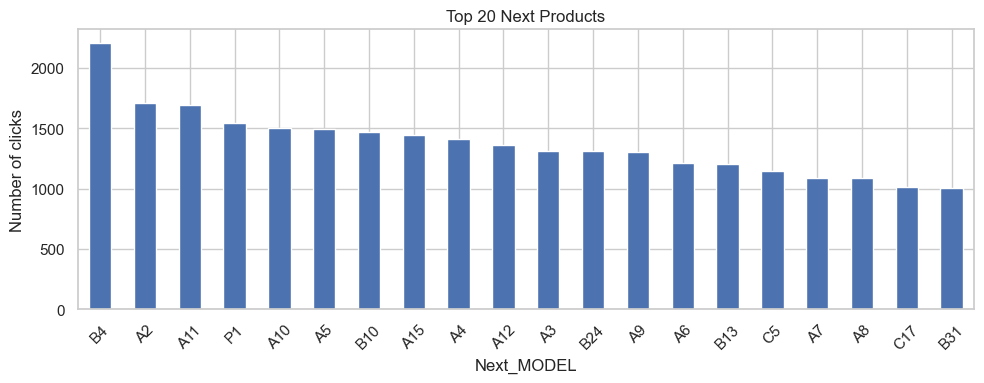

In [7]:
# Target distribution
target_counts = eda["Next_MODEL"].value_counts()

print("Number of classes:", len(target_counts))
print("Classes with <20 clicks:", (target_counts < 20).sum())
print("Classes with <50 clicks:", (target_counts < 50).sum())

# Popularity Coverage@K
popularity_coverage = {}

for k in [1, 3, 5, 10]:
    coverage = target_counts.head(k).sum() / len(eda)
    popularity_coverage[k] = coverage
    print(f"Coverage@{k}: {coverage:.2%}")

popularity_coverage = pd.Series(popularity_coverage)

# Top 20 most popular next products
plt.figure(figsize=(10, 4))
target_counts.head(20).plot(kind="bar")

plt.title("Top 20 Next Products")
plt.xlabel("Next_MODEL")
plt.ylabel("Number of clicks")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The full dataset contains 217 products, while 216 occur as training targets. Three target classes have fewer than 20 training clicks. The five most popular targets cover just 7.69% of training clicks, indicating that one global list captures a small share of next clicks.

Current-to-next product transitions test whether conditioning on the current product gives a more focused candidate list than global popularity.

In [8]:
# Transition probabilities
transition_counts = pd.crosstab(eda["MODEL"], eda["Next_MODEL"])
transition_probs = transition_counts.div(
    transition_counts.sum(axis=1), axis=0
)

# Top 10 most frequent transitions
top_transitions = (
    eda.groupby(["MODEL", "Next_MODEL"], observed=True)
    .size()
    .nlargest(10)
    .reset_index(name="Transitions")
)
display(top_transitions)

# Same product rate
same_model = (eda["MODEL"] == eda["Next_MODEL"]).mean()
print(f"Same MODEL rate: {same_model:.2%}")

# Markov Coverage@K
weights = transition_counts.sum(axis=1) / len(eda)
markov_coverage = {}

for k in [1, 3, 5, 10]:
    top_k_probs = transition_probs.apply(
        lambda row: row.nlargest(k).sum(), axis=1
    )
    markov_coverage[k] = (top_k_probs * weights).sum()

# Compare with Global Popularity
coverage_table = pd.DataFrame({
    "Popularity": popularity_coverage,
    "Markov": pd.Series(markov_coverage)
})

coverage_table.index.name = "K"
display(coverage_table.style.format("{:.2%}"))

,MODEL,Next_MODEL,Transitions
0,A1,A2,532
1,A2,A3,473
2,P1,P2,330
3,A5,A6,326
4,A7,A8,265
5,A9,A10,253
6,B10,B11,250
7,A3,A5,248
8,A8,A9,241
9,B10,B13,226


Same MODEL rate: 5.27%


,Popularity,Markov
K,,
1,1.96%,13.30%
3,4.98%,27.98%
5,7.69%,38.13%
10,14.06%,54.87%


Product transitions show sequential structure: A1 → A2 occurs 532 times, and the same-product rate is 5.27%. The most frequent next products also vary by current product. First-Order Markov Coverage@5 reaches 38.13% on training clicks, compared with 7.69% for Global Popularity. These figures motivate conditional ranking but are not validation or test performance.

### 4.2. Sequential browsing behavior
The next table compares common next products for the same current product under different preceding products. History groups with fewer than 50 clicks are omitted from this display only.

In [9]:
# Top 3 most popular current products
top_models = eda["MODEL"].value_counts().head(3).index

history_rows = []

for model in top_models:
    subset = eda[eda["MODEL"] == model]

    # Top 5 next products, regardless of previous product
    top5 = subset["Next_MODEL"].value_counts().head(5).index
    history_rows.append([
        model, "All previous products", len(subset),
        ", ".join(top5)
    ])

    # Top 2 previous products with at least 50 observations
    previous_counts = subset["Previous_MODEL"].value_counts()
    previous_models = previous_counts[previous_counts >= 50].head(2).index

    for previous in previous_models:
        pair = subset[subset["Previous_MODEL"] == previous]
        top5 = pair["Next_MODEL"].value_counts().head(5).index

        history_rows.append([
            model, previous, len(pair), ", ".join(top5)
        ])

history_table = pd.DataFrame(
    history_rows,
    columns=[
        "Current_MODEL", "Previous_MODEL",
        "Count", "Top_5_next_products"
    ]
)

display(history_table)

,Current_MODEL,Previous_MODEL,Count,Top_5_next_products
0,B4,All previous products,2432,"B3, B4, B2, B10, B9"
1,B4,B3,144,"B5, B6, B9, B3, B2"
2,B4,B1,122,"B10, B9, B13, B17, B2"
3,A2,All previous products,2104,"A3, A5, A11, A2, A4"
4,A2,A1,513,"A3, A5, A4, A11, A2"
5,A2,A2,105,"A3, A2, A4, A5, A11"
6,A11,All previous products,1932,"A12, A10, A11, A15, A13"
7,A11,A10,214,"A12, A11, A13, A14, A5"
8,A11,A2,113,"A10, A5, A13, A11, A3"


For a fixed current product, the most common next products change with the previous product. This association suggests a possible history signal, but its incremental predictive value must be tested by feature ablation.

Category transitions show how often the next click stays within the current category.

Same-category rate: 81.12%


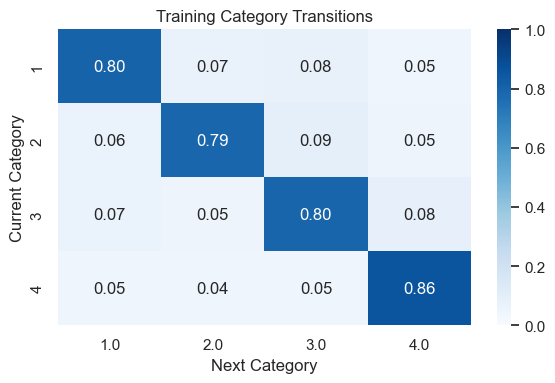

In [10]:
same_category_rate = (eda["CATEGORY"] == eda["Next_CATEGORY"]).mean()
print(f"Same-category rate: {same_category_rate:.2%}")

category_probs = pd.crosstab(
    eda["CATEGORY"], eda["Next_CATEGORY"], normalize="index"
)

plt.figure(figsize=(6, 4))
sns.heatmap(category_probs, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Training Category Transitions")
plt.xlabel("Next Category")
plt.ylabel("Current Category")
plt.tight_layout()
plt.show()


About 81.12% of training next clicks stay within the current category. This continuity may support ranking, although catalogue layout and navigation can also contribute to the pattern.

### 4.3. Product attributes
Colour and price are examined as descriptive signals. Their contribution to ranking is assessed in the feature-ablation experiment.

In [11]:
# Colour distributions
colour_distribution = pd.DataFrame({
    "Current": eda["COLOUR"].value_counts(normalize=True),
    "Next": eda["Next_COLOUR"].value_counts(normalize=True)
}).fillna(0)

# Same-colour rate and independent baseline
same_colour_rate = (
    eda["COLOUR"] == eda["Next_COLOUR"]
).mean()

independent_colour_rate = (
    colour_distribution["Current"] *
    colour_distribution["Next"]
).sum()

print(f"Same-colour rate: {same_colour_rate:.2%}")
print(f"Independent baseline: {independent_colour_rate:.2%}")


Same-colour rate: 25.64%
Independent baseline: 11.06%


Consecutive clicks share a colour 25.64% of the time, compared with 11.06% under the marginal-distribution independence benchmark. Product availability, category and browsing paths may also explain this association.

The following price analysis compares the current and next clicked products.

In [12]:
# Correlation between current and next prices
corr = eda["PRICE"].corr(eda["Next_PRICE"], method="spearman")
print(f"Spearman correlation: {corr:.3f}")

# Price changes
delta = eda["Next_PRICE"] - eda["PRICE"]

price_direction = pd.Series({
    "Cheaper": (delta < 0).mean(),
    "Equal": (delta == 0).mean(),
    "More expensive": (delta > 0).mean()
})

display(price_direction.round(4))


Spearman correlation: 0.188


Cheaper           0.3929
Equal             0.2175
More expensive    0.3896
dtype: float64

Current and next prices have a weak positive Spearman correlation (0.188); cheaper and more expensive next clicks occur at similar rates (39.3% and 39.0%). Price may carry some signal, but the ablation experiment is needed to assess its contribution to ranking.

### 4.4. EDA summary
Training target popularity is dispersed, while current-to-next product transitions and category continuity are pronounced. Previous-product patterns and colour and price associations suggest possible additional information. These descriptive observations motivate controlled baseline and feature-ablation comparisons; grouped CV and held-out evaluation assess predictive performance.

## 5. Methodology
Each method scores candidate products and ranks them by score; ties use lexicographic product codes. Score columns are mapped to the fitted product classes. `LinearSVC` margins are ranking scores, not calibrated probabilities. The actual next product is a miss if it is absent from the fitted classes or outside the Top-K list.

**Hit Rate@5** measures inclusion in the first five ranks. **MRR@10** rewards earlier ranks and assigns zero when the target is outside the first ten. Hit Rate@1, Hit Rate@3/10, Accuracy and Macro F1 provide additional diagnostics. Accuracy and Macro F1 use the first ranked item. Preprocessing is fitted within each training fold; categorical IDs are encoded as categories, and numerical features are scaled for linear models.

In [13]:
def rank_scores(scores, classes, k=10):
    classes = np.asarray(classes).astype(str)
    scores = np.asarray(scores)
    assert scores.ndim == 2 and scores.shape[1] == len(classes)
    assert len(set(classes)) == len(classes) and np.isfinite(scores).all()

    alphabetical = np.argsort(classes, kind="stable")
    order = np.argsort(
        -scores[:, alphabetical], axis=1, kind="stable"
    )[:, :min(k, len(classes))]
    return classes[alphabetical][order]


def rank_predictions(estimator, X, k=10):
    classes = estimator.classes_
    if hasattr(estimator, "predict_proba"):
        scores = estimator.predict_proba(X)
    else:
        scores = estimator.decision_function(X)
        if np.ndim(scores) == 1:
            assert len(classes) == 2
            scores = np.column_stack([-scores, scores])
    return rank_scores(scores, classes, k)


def ranking_metrics(y, ranked):
    y = np.asarray(y).astype(str)
    assert len(y) == len(ranked) and ranked.shape[1] > 0

    matches = ranked[:, :10] == y[:, None]
    result = {
        f"Hit Rate@{k}": matches[:, :k].any(axis=1).mean()
        for k in [1, 3, 5, 10]
    }
    result["MRR@10"] = np.where(
        matches.any(axis=1), 1 / (matches.argmax(axis=1) + 1), 0
    ).mean()
    result["Accuracy"] = accuracy_score(y, ranked[:, 0])
    result["Macro F1"] = f1_score(
        y, ranked[:, 0], average="macro", zero_division=0
    )
    return result


def score_estimator(estimator, X, y):
    # Score each validation partition from one ranked prediction array.
    return ranking_metrics(y, rank_predictions(estimator, X))


def hit_rate_5_scorer(estimator, X, y):
    ranked = rank_predictions(estimator, X, k=5)
    return (ranked == np.asarray(y).astype(str)[:, None]).any(axis=1).mean()


def evaluate_cv(estimator, X, y):
    result = cross_validate(
        estimator, X, y, cv=folds, scoring=score_estimator,
        n_jobs=1, error_score="raise"
    )
    return pd.DataFrame(
        {key[5:]: value for key, value in result.items() if key.startswith("test_")},
        index=pd.Index(range(1, 6), name="Fold")
    )


### Ranking baselines
Global Popularity ranks products by their training-fold frequencies. First-Order Markov ranks them by observed next-product frequencies conditional on the current product, falling back to global popularity for an unseen current product. Both are fitted within each training fold and use the same ranking tie rule as the ML models.

In [14]:
class MarkovBaseline(ClassifierMixin, BaseEstimator):
    def fit(self, X, y):
        data = pd.DataFrame({"MODEL": X["MODEL"].to_numpy(), "Next_MODEL": np.asarray(y)})
        self.classes_ = np.sort(data["Next_MODEL"].unique())
        self.prior_ = data["Next_MODEL"].value_counts(normalize=True).reindex(self.classes_).to_numpy()
        counts = pd.crosstab(data["MODEL"], data["Next_MODEL"]).reindex(columns=self.classes_, fill_value=0)
        self.transitions_ = counts.div(counts.sum(axis=1), axis=0)
        return self

    def predict_proba(self, X):
        scores = self.transitions_.reindex(X["MODEL"].astype(object)).to_numpy().copy()
        scores[np.isnan(scores).any(axis=1)] = self.prior_
        return scores

    def predict(self, X):
        return rank_predictions(self, X, k=1)[:, 0]


baselines = {"Global Popularity": DummyClassifier(strategy="prior"), "First-Order Markov": MarkovBaseline()}


## 6. Model experiments
### 6.1. Model comparison
The same 13-feature input and grouped folds are used to compare the two baselines with Logistic Regression, Decision Tree, Random Forest and LinearSVC. The baselines use only the fields they need. Logistic Regression and LinearSVC provide linear score-based rankings; Decision Tree and Random Forest capture nonlinear feature interactions. The best ML family is selected by mean CV Hit Rate@5, then MRR@10. Baseline results remain visible even when an ML family is selected for later experiments.

In [15]:
model_settings = {
    "Logistic Regression": LogisticRegression(
        C=1.0, solver="lbfgs", max_iter=1000, tol=0.005,
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=16, min_samples_leaf=10, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=60, max_depth=16, min_samples_leaf=5,
        max_features="sqrt", n_jobs=2, random_state=RANDOM_STATE
    ),
    "LinearSVC": LinearSVC(
        C=1.0, max_iter=10000, tol=0.001, random_state=RANDOM_STATE
    )
}


def make_pipeline(model_name, features):
    cat = [f for f in features if f in categorical_features]
    num = [f for f in features if f in numerical_features]
    assert set(cat + num) == set(features)

    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if model_name in ["Logistic Regression", "LinearSVC"]:
        numeric_steps.append(("scaler", StandardScaler()))

    preprocessor = ColumnTransformer([
        ("num", Pipeline(numeric_steps), num),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="START")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat)
    ])
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", clone(model_settings[model_name]))
    ])


models = {
    **baselines,
    **{name: make_pipeline(name, all_features) for name in model_settings}
}
model_cv_scores = {}


In [16]:
for name, estimator in models.items():
    model_cv_scores[name] = evaluate_cv(estimator, X_train, y_train)


In [17]:
model_comparison = pd.DataFrame({
    name: scores.mean() for name, scores in model_cv_scores.items()
}).T
model_comparison["HR5_std"] = pd.Series({
    name: scores["Hit Rate@5"].std()
    for name, scores in model_cv_scores.items()
})
model_comparison = model_comparison.sort_values(
    ["Hit Rate@5", "MRR@10"], ascending=False, kind="stable"
)

display(model_comparison[
    ["Hit Rate@5", "HR5_std", "MRR@10", "Accuracy", "Macro F1"]
].round(4))
selected_name = model_comparison.loc[
    model_comparison.index.isin(model_settings)
].index[0]


,Hit Rate@5,HR5_std,MRR@10,Accuracy,Macro F1
First-Order Markov,0.3656,0.0015,0.2319,0.1292,0.0890
Random Forest,0.3649,0.0013,0.2356,0.1359,0.0984
Logistic Regression,0.3469,0.0019,0.2214,0.1245,0.0774
LinearSVC,0.3378,0.0020,0.2195,0.1293,0.1030
Decision Tree,0.3101,0.0031,0.2044,0.1219,0.1015
Global Popularity,0.0763,0.0019,0.0464,0.0196,0.0002


Random Forest has the highest grouped CV Hit Rate@5 among the ML candidates (36.49%). First-Order Markov ranks slightly higher overall at 36.56%, compared with 36.49% for untuned Random Forest. The displayed fold standard deviations describe variation across these five folds, not confidence intervals.

### 6.2. Feature ablation
For the selected ML family, E1–E5 compare feature groups on identical grouped CV folds with unchanged model parameters.

| Experiment | Features |
| --- | --- |
| E1 | Current product |
| E2 | Current product + browsing context |
| E3 | E2 + product history |
| E4 | E3 + price history |
| E5 | Current product + product history |

E4 reuses the model-comparison score. Selection uses mean Hit Rate@5, then MRR@10, then fewer features. Differences describe conditional predictive contributions for this model and feature set; they do not establish causal effects.

In [18]:
experiment_features = {
    "E1": product_features,
    "E2": product_features + context_features,
    "E3": product_features + context_features + product_history,
    "E4": all_features,
    "E5": product_features + product_history
}
ablation_scores = {"E4": model_cv_scores[selected_name].copy()}

In [19]:
for experiment, features in experiment_features.items():
    if experiment == "E4":
        continue  # E4 reuses the full-feature model comparison result.
    ablation_scores[experiment] = evaluate_cv(
        make_pipeline(selected_name, features),
        train_df[features],
        y_train
    )


,Features,Hit Rate@5,HR5_std,MRR@10,Accuracy,HR5_gain_vs_E1_pp
E1,5,0.3604,0.0038,0.2283,0.1273,0.0000
E2,9,0.3435,0.0027,0.2202,0.1249,-1.6979
E3,11,0.3644,0.0012,0.2346,0.1351,0.3983
E4,13,0.3649,0.0013,0.2356,0.1359,0.4436
E5,7,0.3387,0.0007,0.2190,0.1273,-2.1780


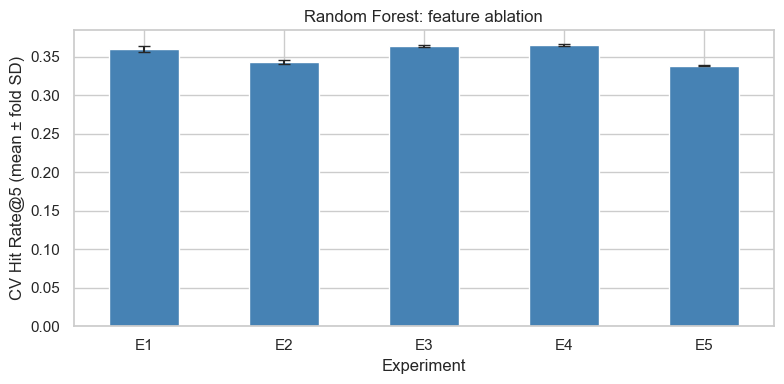

,HR5_difference_pp
Context: E2 minus E1,-1.698
History with context: E3 minus E2,2.096
Price history: E4 minus E3,0.045
History alone: E5 minus E1,-2.178


In [20]:
ablation_table = pd.DataFrame({
    name: scores.mean() for name, scores in ablation_scores.items()
}).T.sort_index()
ablation_table["HR5_std"] = pd.Series({
    name: scores["Hit Rate@5"].std()
    for name, scores in ablation_scores.items()
})
ablation_table["Features"] = pd.Series({
    name: len(features) for name, features in experiment_features.items()
})
ablation_table["HR5_gain_vs_E1_pp"] = 100 * (
    ablation_table["Hit Rate@5"] - ablation_table.loc["E1", "Hit Rate@5"]
)
display(ablation_table[
    ["Features", "Hit Rate@5", "HR5_std", "MRR@10", "Accuracy", "HR5_gain_vs_E1_pp"]
].round(4))

selected_experiment = ablation_table.sort_values(
    ["Hit Rate@5", "MRR@10", "Features"],
    ascending=[False, False, True],
    kind="stable"
).index[0]
selected_features = experiment_features[selected_experiment].copy()

fig, ax = plt.subplots(figsize=(8, 4))
ablation_table["Hit Rate@5"].plot.bar(
    yerr=ablation_table["HR5_std"], capsize=4, color="steelblue", ax=ax
)
ax.set(
    title=f"{selected_name}: feature ablation",
    xlabel="Experiment",
    ylabel="CV Hit Rate@5 (mean ± fold SD)"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

feature_effects = pd.Series({
    "Context: E2 minus E1": 100 * (
        ablation_table.loc["E2", "Hit Rate@5"] - ablation_table.loc["E1", "Hit Rate@5"]
    ),
    "History with context: E3 minus E2": 100 * (
        ablation_table.loc["E3", "Hit Rate@5"] - ablation_table.loc["E2", "Hit Rate@5"]
    ),
    "Price history: E4 minus E3": 100 * (
        ablation_table.loc["E4", "Hit Rate@5"] - ablation_table.loc["E3", "Hit Rate@5"]
    ),
    "History alone: E5 minus E1": 100 * (
        ablation_table.loc["E5", "Hit Rate@5"] - ablation_table.loc["E1", "Hit Rate@5"]
    )
}, name="HR5_difference_pp")
display(feature_effects.to_frame().round(3))


E4 is selected under the predefined CV rule, but its advantage over E3 is only 0.045 percentage points. This small difference does not establish a meaningful benefit from adding price history. The feature-group differences are descriptive comparisons on the same folds.

### 6.3. Hyperparameter tuning
In the saved run, Random Forest is the selected ML family. `RandomizedSearchCV` samples 10 configurations from the parameter space shown below. Each candidate uses the same five session-grouped CV partitions; mean Hit Rate@5 selects and refits the final configuration on all training data. MRR@10 is reported as a secondary metric. The selected CV score may be optimistic because the folds also informed earlier choices.

In [21]:
X_train_selected = train_df[selected_features]
param_space = {
    "model__n_estimators": [60, 100, 150],
    "model__max_depth": [12, 16, 20, 24],
    "model__min_samples_leaf": [1, 2, 3, 5, 10],
    "model__min_samples_split": [2, 5, 10],
    "model__max_features": ["sqrt", "log2", 0.3],
    "model__max_samples": [None, 0.7, 0.9],
}

def mrr10_scorer(estimator, X, y):
    return ranking_metrics(y, rank_predictions(estimator, X))["MRR@10"]


In [22]:
search = RandomizedSearchCV(
    make_pipeline(selected_name, selected_features),
    param_space,
    n_iter=10,
    scoring={"Hit Rate@5": hit_rate_5_scorer, "MRR@10": mrr10_scorer},
    refit="Hit Rate@5",
    cv=folds,  # Reuse the fixed session-grouped partitions.
    random_state=RANDOM_STATE,
    n_jobs=1,
    error_score="raise",
)
search.fit(X_train_selected, y_train)

best_model = search.best_estimator_
print("Best parameters:", search.best_params_)

tuning_results = (
    pd.DataFrame(search.cv_results_)[[
        "rank_test_Hit Rate@5", "mean_test_Hit Rate@5",
        "std_test_Hit Rate@5", "mean_test_MRR@10",
        "mean_fit_time", "params"
    ]]
    .sort_values("rank_test_Hit Rate@5")
)
pd.set_option("display.max_colwidth", None)
display(tuning_results.round(4))


Best parameters: {'model__n_estimators': 150, 'model__min_samples_split': 5, 'model__min_samples_leaf': 3, 'model__max_samples': None, 'model__max_features': 'sqrt', 'model__max_depth': 24}


,rank_test_Hit Rate@5,mean_test_Hit Rate@5,std_test_Hit Rate@5,mean_test_MRR@10,mean_fit_time,params
9,1,0.3740,0.0011,0.2429,31.5882,"{'model__n_estimators': 150, 'model__min_samples_split': 5, 'model__min_samples_leaf': 3, 'model__max_samples': None, 'model__max_features': 'sqrt', 'model__max_depth': 24}"
3,2,0.3728,0.0009,0.2411,13.6145,"{'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 5, 'model__max_samples': 0.7, 'model__max_features': 'sqrt', 'model__max_depth': 24}"
2,3,0.3702,0.0017,0.2416,34.4763,"{'model__n_estimators': 150, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_samples': 0.7, 'model__max_features': 'sqrt', 'model__max_depth': 20}"
8,4,0.3677,0.0008,0.2377,8.9293,"{'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_samples': 0.7, 'model__max_features': 'sqrt', 'model__max_depth': 16}"
4,5,0.3647,0.0018,0.2391,154.9193,"{'model__n_estimators': 150, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_samples': 0.7, 'model__max_features': 0.3, 'model__max_depth': 20}"
0,6,0.3622,0.0020,0.2363,137.5815,"{'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_samples': 0.7, 'model__max_features': 0.3, 'model__max_depth': 20}"
1,7,0.3613,0.0013,0.2328,6.2848,"{'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 3, 'model__max_samples': 0.9, 'model__max_features': 'log2', 'model__max_depth': 24}"
5,8,0.3599,0.0013,0.2367,64.8917,"{'model__n_estimators': 60, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_samples': None, 'model__max_features': 0.3, 'model__max_depth': 20}"
7,9,0.3528,0.0010,0.2270,5.1893,"{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 5, 'model__max_samples': 0.9, 'model__max_features': 'sqrt', 'model__max_depth': 12}"
6,10,0.3511,0.0030,0.2261,3.4999,"{'model__n_estimators': 60, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_samples': 0.9, 'model__max_features': 'log2', 'model__max_depth': 20}"


The best searched configuration raises mean training-CV Hit Rate@5 from 36.49% for the untuned E4 model to 37.40%, a gain of 0.917 percentage points. Reusing the selection folds may make the tuned CV estimate optimistic.

## 7. Model evaluation
### 7.1. Final test performance
In this completed run, the selected features and tuned Random Forest are evaluated against Global Popularity, First-Order Markov and the untuned Random Forest on the same held-out clicks. An unseen target counts as a miss. This holdout was inspected in earlier project development, so these results are descriptive rather than independent confirmation.

In [23]:
# Prepare aligned test inputs for baselines and the selected ML model.
y_test = test_df["Next_MODEL"]
X_test_all = test_df[all_features]  # Baselines use the complete feature frame.
X_test_sel = test_df[selected_features]  # Selected features for both ML rankings.
assert X_test_sel.index.equals(y_test.index)

# Fit the baselines and untuned model on training data; reuse the search refit.
ml_label = "Tuned " + selected_name
untuned_label = "Untuned " + selected_name

final_estimators = {
    name: clone(est).fit(X_train, y_train)
    for name, est in baselines.items()
}
final_estimators[untuned_label] = make_pipeline(
    selected_name, selected_features
).fit(X_train_selected, y_train)
final_estimators[ml_label] = best_model  # Already refitted on all training rows.

# Rank once per model, then reuse the lists for every metric.
test_rankings = {}
for name, est in final_estimators.items():
    X_eval = X_test_sel if name in (ml_label, untuned_label) else X_test_all
    test_rankings[name] = rank_predictions(est, X_eval)


In [24]:
# Compare all methods on the same held-out observations.
test_results = pd.DataFrame(
    {
        name: ranking_metrics(y_test, ranked)
        for name, ranked in test_rankings.items()
    }
).T
metric_order = [
    "Accuracy", "Macro F1", "Hit Rate@1", "Hit Rate@3",
    "Hit Rate@5", "Hit Rate@10", "MRR@10"
]
display(test_results[metric_order].round(4))

# Unseen target labels remain evaluation misses.
unseen_test_classes = sorted(set(y_test) - set(best_model.classes_))
print("Test targets absent from fitted ML classes:", unseen_test_classes)
print("Their test rows (retained):", y_test.isin(unseen_test_classes).sum())
assert not np.isin(
    np.asarray(unseen_test_classes), test_rankings[ml_label]
).any()


,Accuracy,Macro F1,Hit Rate@1,Hit Rate@3,Hit Rate@5,Hit Rate@10,MRR@10
Global Popularity,0.0175,0.0002,0.0175,0.0484,0.0760,0.1407,0.0451
First-Order Markov,0.1314,0.0920,0.1314,0.2761,0.3750,0.5361,0.2376
Untuned Random Forest,0.1391,0.1019,0.1391,0.2802,0.3743,0.5283,0.2416
Tuned Random Forest,0.1476,0.1243,0.1476,0.2918,0.3858,0.5411,0.2513


Test targets absent from fitted ML classes: ['P54']
Their test rows (retained): 1


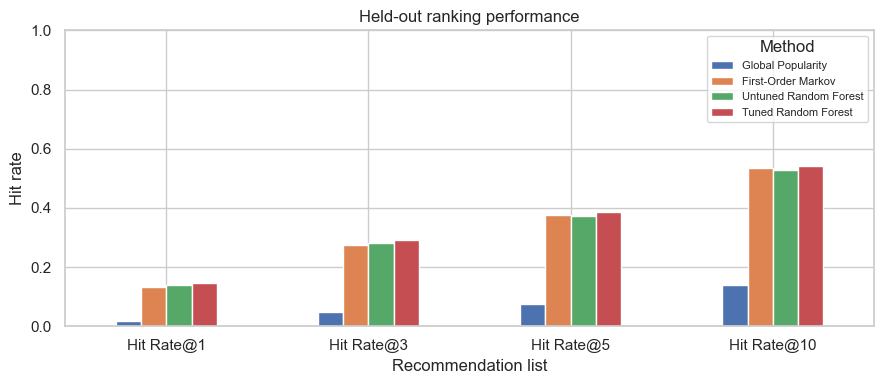

In [25]:
# Visualize held-out ranking performance.
hit_cols = ["Hit Rate@1", "Hit Rate@3", "Hit Rate@5", "Hit Rate@10"]
fig, ax = plt.subplots(figsize=(9, 4))
test_results[hit_cols].T.plot.bar(ax=ax)
ax.set(
    title="Held-out ranking performance",
    xlabel="Recommendation list",
    ylabel="Hit rate",
    ylim=(0, 1)
)
plt.xticks(rotation=0)
plt.legend(title="Method", fontsize=8)
plt.tight_layout()
plt.show()


Tuned Random Forest reaches **38.58% Hit Rate@5** on the held-out test set, compared with **37.50%** for First-Order Markov and **37.43%** for the untuned Random Forest. Its +1.08 pp margin over Markov is small; the session bootstrap below quantifies sampling uncertainty around this difference. Global Popularity reaches 7.60%. The single test target absent from training (`P54`) remains a miss for every model.

### 7.2. Bootstrap uncertainty analysis
Clicks in the same test session may be correlated. To assess uncertainty in the **click-weighted Hit Rate@5 difference** between the frozen tuned Random Forest and First-Order Markov rankings, we resample complete test sessions with replacement. Both methods use the same 2,000 sampled session sets; repeated sessions contribute all their clicks each time. The interval is a percentile bootstrap confidence interval for the difference in percentage points.

In [26]:
# Reuse the held-out Top-10 rankings; neither model is fitted in this analysis.
assert test_df.index.equals(y_test.index)
assert test_df["SESSION_ID"].notna().all()

rf_ranked = test_rankings[ml_label]
markov_ranked = test_rankings["First-Order Markov"]
assert rf_ranked.shape == markov_ranked.shape == (len(y_test), 10)

targets = y_test.to_numpy().astype(str)
rf_hits = (rf_ranked[:, :5] == targets[:, None]).any(axis=1)
markov_hits = (markov_ranked[:, :5] == targets[:, None]).any(axis=1)
rf_hr5, markov_hr5 = rf_hits.mean(), markov_hits.mean()
for label, ranked, observed in [
    (ml_label, rf_ranked, rf_hr5),
    ("First-Order Markov", markov_ranked, markov_hr5),
]:
    assert np.isclose(observed, test_results.loc[label, "Hit Rate@5"], rtol=0, atol=1e-12)

session_codes, test_sessions = pd.factorize(test_df["SESSION_ID"], sort=False)
n_sessions = len(test_sessions)
clicks_per_session = np.bincount(session_codes, minlength=n_sessions)
rf_hits_per_session = np.bincount(session_codes, weights=rf_hits.astype(int), minlength=n_sessions).astype(int)
markov_hits_per_session = np.bincount(session_codes, weights=markov_hits.astype(int), minlength=n_sessions).astype(int)
assert clicks_per_session.sum() == len(y_test)
assert rf_hits_per_session.sum() == rf_hits.sum()
assert markov_hits_per_session.sum() == markov_hits.sum()

n_bootstrap = 2000
rng = np.random.default_rng(42)
bootstrap_differences_pp = np.empty(n_bootstrap)
for b in range(n_bootstrap):
    sampled_sessions = rng.integers(0, n_sessions, size=n_sessions)
    sampled_clicks = clicks_per_session[sampled_sessions].sum()
    bootstrap_differences_pp[b] = 100 * (
        rf_hits_per_session[sampled_sessions].sum()
        - markov_hits_per_session[sampled_sessions].sum()
    ) / sampled_clicks

observed_difference_pp = 100 * (rf_hr5 - markov_hr5)
bootstrap_mean_pp = bootstrap_differences_pp.mean()
bootstrap_sd_pp = bootstrap_differences_pp.std(ddof=1)
ci_lower_pp, ci_upper_pp = np.percentile(bootstrap_differences_pp, [2.5, 97.5])
assert np.isfinite([bootstrap_mean_pp, bootstrap_sd_pp, ci_lower_pp, ci_upper_pp]).all()
assert ci_lower_pp <= ci_upper_pp

,Value
Metric,
RF Hit Rate@5,38.5848%
Markov Hit Rate@5,37.5039%
Observed difference (pp),+1.0809
Bootstrap mean difference (pp),+1.0798
Bootstrap SD (pp),0.1637
95% CI lower bound (pp),+0.7752
95% CI upper bound (pp),+1.4249
Bootstrap replications,"2,000"
Resampling unit,Session


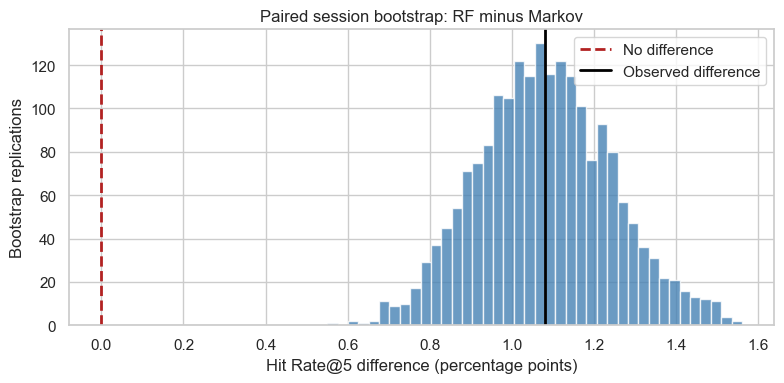

In [27]:
bootstrap_summary = pd.DataFrame({
    "Metric": [
        "RF Hit Rate@5", "Markov Hit Rate@5", "Observed difference (pp)",
        "Bootstrap mean difference (pp)", "Bootstrap SD (pp)",
        "95% CI lower bound (pp)", "95% CI upper bound (pp)",
        "Bootstrap replications", "Resampling unit", "Unique test sessions"
    ],
    "Value": [
        f"{rf_hr5:.4%}", f"{markov_hr5:.4%}", f"{observed_difference_pp:+.4f}",
        f"{bootstrap_mean_pp:+.4f}", f"{bootstrap_sd_pp:.4f}",
        f"{ci_lower_pp:+.4f}", f"{ci_upper_pp:+.4f}",
        f"{n_bootstrap:,}", "Session", f"{n_sessions:,}"
    ]
}).set_index("Metric")
display(bootstrap_summary)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(bootstrap_differences_pp, bins=40, color="steelblue", alpha=0.8)
ax.axvline(0, color="firebrick", linestyle="--", linewidth=2, label="No difference")
ax.axvline(observed_difference_pp, color="black", linewidth=2, label="Observed difference")
ax.set(
    title="Paired session bootstrap: RF minus Markov",
    xlabel="Hit Rate@5 difference (percentage points)",
    ylabel="Bootstrap replications"
)
ax.legend()
plt.tight_layout()
plt.show()


The observed tuned Random Forest advantage over First-Order Markov is +1.0809 percentage points. The 95% percentile bootstrap interval is [+0.7752, +1.4249] percentage points, entirely above zero. This supports a positive difference for the fixed rankings under session resampling; it does not establish business impact, and the holdout was previously inspected.

### 7.3. Error analysis
The following slices describe the frozen tuned-model rankings on the test set. They are exploratory and do not guide further tuning. **Browsing stage** uses Early, Middle and Late click positions.

In [28]:
ml_ranked = test_rankings[ml_label]
hit5 = (ml_ranked[:, :5] == y_test.to_numpy()[:, None]).any(axis=1)

error_df = test_df[["ORDER", "CATEGORY", "Next_MODEL"]].assign(
    Hit5=hit5,
    Stage=pd.cut(test_df["ORDER"], [0, 3, 10, np.inf], labels=["Early", "Middle", "Late"]),
)

stage_results = (
    error_df.groupby("Stage", observed=True)["Hit5"]
    .agg(**{"Hit Rate@5": "mean", "Clicks": "size"})
)
display(stage_results.round(4))

,Hit Rate@5,Clicks
Stage,,
Early,0.3616,9531
Middle,0.3685,10329
Late,0.4310,9097


Hit Rate@5 is 36.2% for Early clicks, 36.9% for Middle and 43.1% for Late. Long sessions contribute more clicks, so the stage difference may reflect session composition as well as click position; it does not establish a causal effect of longer browsing.

**Current product category.** These groups describe the category of the present click, not a restriction on the next product.

In [29]:
category_results = (
    error_df.groupby("CATEGORY", observed=True)["Hit5"]
    .agg(["mean", "size"])
    .rename(columns={"mean": "Hit Rate@5", "size": "Clicks"})
)
display(category_results.round(4))


,Hit Rate@5,Clicks
CATEGORY,,
1,0.4143,9033
2,0.4061,6474
3,0.3350,6771
4,0.3794,6679


Hit Rate@5 ranges from 33.5% in Category 3 to 41.4% in Category 1. Each category has substantial test support, but the difference may reflect product and session composition rather than category alone.

**Frequently missed products.** The next table separates high miss counts from low per-product hit rates.

In [30]:
missed_products = error_df.groupby("Next_MODEL")["Hit5"].agg(
    ["size", "sum", "mean"]
)
missed_products["Misses"] = missed_products["size"] - missed_products["sum"]
missed_products = missed_products.rename(columns={
    "size": "Test_clicks",
    "sum": "Hits",
    "mean": "Hit Rate@5"
})
display(missed_products.sort_values("Misses", ascending=False).head(15).round(4))


,Test_clicks,Hits,Hit Rate@5,Misses
Next_MODEL,,,,
B4,506,184,0.3636,322
P1,391,135,0.3453,256
A4,347,105,0.3026,242
A2,454,214,0.4714,240
A15,375,152,0.4053,223
A1,215,10,0.0465,205
A5,424,236,0.5566,188
B1,194,6,0.0309,188
A13,237,59,0.2489,178


Frequent products such as B4 and P1 produce many misses partly because they have many test clicks. A1 and B1 are more distinctive: Hit Rate@5 is only 4.7% and 3.1%, respectively, despite 215 and 194 test clicks. High miss counts alone therefore do not identify the hardest products.

In [31]:
for product in ["A1", "B1"]:
    product_clicks = test_df[test_df["Next_MODEL"] == product]
    print(product, "- median ORDER of preceding click:", product_clicks["ORDER"].median())
    print(product_clicks["MODEL"].value_counts().head(5), "\n")


A1 - median ORDER of preceding click: 3.0
MODEL
A2     24
A11    17
A1     16
A4     14
A3     10
Name: count, dtype: int64 

B1 - median ORDER of preceding click: 5.0
MODEL
B4     18
B16    10
B1     10
B17     9
B10     8
Name: count, dtype: int64 



A1 and B1 are not confined to first-click positions: the preceding click has median `ORDER` 3 and 5, respectively. Their preceding products are dispersed. Return navigation is one possible explanation, but the data contain no indicator that would test it.

**Prediction concentration and catalogue coverage.** Catalogue Coverage@5 is the share of training-known products recommended at least once. The eligible catalogue includes codes from complete training sessions; unseen test products remain ranking misses.

In [32]:
# Count how often each product occupies a Top-5 recommendation slot.
top5 = ml_ranked[:, :5].ravel()
slot_counts = pd.Series(top5).value_counts()
total_slots = slot_counts.sum()

# Use products observed in complete training sessions as the eligible catalogue.
catalogue = set(train_clicks["MODEL"]) | set(y_train)
assert set(slot_counts.index) <= catalogue

coverage = len(slot_counts) / len(catalogue)
top10_model_share = slot_counts.head(10).sum() / total_slots
top10_train = target_counts.head(10).index
top10_train_share = (
    slot_counts[slot_counts.index.isin(top10_train)].sum() / total_slots
)

summary = pd.Series({
    "Eligible_products": len(catalogue),
    "Distinct_recommended": len(slot_counts),
    "Catalogue_Coverage@5": coverage,
    "Top10_recommended_slot_share": top10_model_share,
    "Top10_train_popular_slot_share": top10_train_share,
})
display(summary.to_frame("Value").round(4))

display(pd.DataFrame({
    "Slots": slot_counts.head(10),
    "Slot_share": slot_counts.head(10) / total_slots,
}).round(4))


,Value
Eligible_products,216.0000
Distinct_recommended,213.0000
Catalogue_Coverage@5,0.9861
Top10_recommended_slot_share,0.1816
Top10_train_popular_slot_share,0.1673


,Slots,Slot_share
A11,4146,0.0286
B10,2893,0.0200
A10,2854,0.0197
B4,2719,0.0188
C17,2662,0.0184
A5,2408,0.0166
A9,2330,0.0161
A12,2189,0.0151
B24,2151,0.0149
A15,1947,0.0134


The tuned model recommends 213 of 216 eligible products at least once (98.6% coverage). Its ten most recommended products occupy 18.2% of Top-5 slots. Broad catalogue coverage does not by itself establish relevance, diversity within a list or user satisfaction.

### 7.4. Feature importance
Permutation importance measures the change in Hit Rate@5 when one feature is shuffled. The existing analysis uses up to 3,000 validation clicks from one training fold and three repeats. That fold also informed selection, so the result is exploratory. Correlated features can mask one another, and independent shuffling can create implausible product-attribute combinations.

In [33]:
importance_tr, importance_va = folds[0]
importance_model = clone(best_model).fit(
    X_train_selected.iloc[importance_tr], y_train.iloc[importance_tr]
)
importance_rows = np.random.default_rng(RANDOM_STATE).choice(
    importance_va, size=min(3000, len(importance_va)), replace=False
)
importance = permutation_importance(
    importance_model,
    X_train_selected.iloc[importance_rows],
    y_train.iloc[importance_rows],
    scoring=hit_rate_5_scorer,
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=1
)
importance_df = pd.DataFrame({
    "Feature": selected_features,
    "HR5_decrease": importance.importances_mean,
    "Repeat_SD": importance.importances_std
}).sort_values("HR5_decrease", ascending=False)
display(importance_df.round(4))


,Feature,HR5_decrease,Repeat_SD
1,CATEGORY,0.1309,0.0024
6,PAGE,0.0234,0.0018
2,COLOUR,0.0116,0.0018
7,LOCATION,0.0110,0.0026
0,MODEL,0.0094,0.0015
3,PRICE,0.0073,0.0005
8,PHOTOGRAPHY,0.0066,0.0023
4,PRICE_2,0.0029,0.0006
9,Previous_MODEL,0.0018,0.0020
12,Average_Previous_Price,0.0008,0.0020


Shuffling `CATEGORY` reduces fold Hit Rate@5 by about 13.1 pp; `PAGE` is next at about 2.3 pp. Most history features have effects near the repeat variation. These values measure sensitivity of this fitted model to the chosen shuffling procedure, not causal or independent contributions. The three-repeat SD does not measure uncertainty across sessions, and small importance differences should not determine feature removal. The grouped ablation provides more direct evidence about feature-group combinations.

### 7.5. Navigation bias analysis
Sequential product clicks may reflect catalogue navigation as well as customer interest. Using the same untuned Random Forest and grouped training folds as E1–E5, N1 tests a **navigation-oriented feature set** (`MODEL`, `PAGE`, `LOCATION`, `ORDER`), while N2 removes `PAGE` and `LOCATION` from E4. `MODEL` also carries product identity and possible interest signals, so neither comparison isolates a causal navigation effect. These training-CV checks do not revise the selected features or held-out rankings.

In [34]:
navigation_features = ["MODEL", "PAGE", "LOCATION", "ORDER"]
no_layout_features = [
    feature for feature in all_features if feature not in ["PAGE", "LOCATION"]
]
assert {"SESSION_ID", "Next_MODEL"}.isdisjoint(navigation_features + no_layout_features)
assert selected_name == "Random Forest" and selected_experiment == "E4"

# E4 was already evaluated in the original ablation; reuse its full-precision folds.
navigation_cv_scores = {"E4": ablation_scores["E4"].copy()}
for experiment, features in {
    "N1": navigation_features,
    "N2": no_layout_features,
}.items():
    navigation_cv_scores[experiment] = evaluate_cv(
        make_pipeline(selected_name, features), X_train[features], y_train
    )
    assert navigation_cv_scores[experiment].index.equals(navigation_cv_scores["E4"].index)
    assert np.isfinite(navigation_cv_scores[experiment][["Hit Rate@5", "MRR@10"]]).all().all()

In [35]:
navigation_labels = {
    "E4": "All features",
    "N1": "Navigation-oriented",
    "N2": "Without PAGE and LOCATION",
}
navigation_results = pd.DataFrame({
    "Feature set": pd.Series(navigation_labels),
    "CV Hit Rate@5": pd.Series({
        name: scores["Hit Rate@5"].mean()
        for name, scores in navigation_cv_scores.items()
    }),
    "CV MRR@10": pd.Series({
        name: scores["MRR@10"].mean()
        for name, scores in navigation_cv_scores.items()
    }),
})
navigation_results["Difference vs E4 (pp)"] = 100 * (
    navigation_results["CV Hit Rate@5"] - navigation_results.loc["E4", "CV Hit Rate@5"]
)
navigation_results.index.name = "Experiment"
display(navigation_results.round({
    "CV Hit Rate@5": 4, "CV MRR@10": 4, "Difference vs E4 (pp)": 3
}))

,Feature set,CV Hit Rate@5,CV MRR@10,Difference vs E4 (pp)
Experiment,,,,
E4,All features,0.3649,0.2356,0.000
N1,Navigation-oriented,0.2933,0.1901,-7.153
N2,Without PAGE and LOCATION,0.3440,0.2233,-2.089


N1 retains about **80%** of E4's CV Hit Rate@5 (29.33% versus 36.49%), but its **7.15 pp** gap shows that the other available features add substantial predictive information. Removing `PAGE` and `LOCATION` lowers CV Hit Rate@5 by **2.09 pp** (N2: 34.40%), suggesting useful incremental layout-related information under this fixed Random Forest configuration. Whether that gain justifies a practical system cannot be determined from offline ranking alone. `MODEL` mixes product identity with possible navigation and interest signals, and correlated features can substitute for one another. These descriptive CV differences do not establish that layout changes cause different clicks or reveal customers' true preferences.

## 8. Discussion

### RQ1. Do Machine Learning models outperform the baselines?
Random Forest leads the ML candidates on grouped CV at 36.49% Hit Rate@5, although First-Order Markov is slightly higher before tuning at 36.56%. On the held-out test, tuned Random Forest reaches 38.58%, compared with 37.50% for Markov and 7.60% for Global Popularity. The paired session bootstrap supports a positive difference for the fixed RF and Markov rankings (95% percentile interval: +0.78 to +1.42 percentage points). The gain remains modest relative to the added model complexity, and the holdout was previously inspected.

### RQ2. Do contextual and historical features improve ranking?
Adding browsing context to current-product features reduces CV Hit Rate@5 by 1.698 percentage points in E2. Adding product history to that set raises it by 2.096 points in E3, while price history adds only 0.045 points in E4. History without context performs 2.178 points below E1. E4 is selected by the predefined CV rule; the value of these feature groups depends on their combination.

### RQ3. How effectively is the next product ranked?
Tuned Random Forest reaches 14.76% Hit Rate@1, 38.58% Hit Rate@5, 54.11% Hit Rate@10 and 0.2513 MRR@10 on the test set. A five-product list therefore contains the actual next clicked product for about 39% of eligible test clicks. MRR@10 also reflects how early the target appears when it is ranked. These outcomes are conditional on another click occurring in the session.

### Practical implications
The Top-K lists provide candidate products for a recommendation interface. Markov offers a simpler conditional baseline, while Random Forest adds fitting and inference costs for a small test gain. Offline next-click ranking does not measure click-through rate, conversion, revenue or customer satisfaction. Catalogue navigation may contribute to the observed patterns; assessing user and business outcomes requires online evaluation.

## 9. Conclusion and limitations
This study constructs a session-based next-product ranking workflow and compares product-level Top-K predictions with simple baselines under grouped validation. In the completed experiment, the tuned Random Forest has a modest held-out advantage over First-Order Markov, while feature ablation shows that the value of context and history depends on their combination. The contribution is an evidence-based offline comparison and candidate-ranking approach, not a demonstrated production recommendation benefit.

### Limitations
The data come from one website in 2008 and contain clicks without purchase or conversion labels. Predictions are conditional on another click; catalogue layout and navigation may contribute to the learned patterns. The holdout was inspected during earlier development, and repeated CV-based choices may make selection estimates optimistic. The bootstrap interval conditions on frozen predictions and does not include uncertainty from model fitting or selection. Offline ranking metrics do not establish business impact.

### Future work
A fresh temporal holdout and online evaluation could test generalization and practical value.